# Notebook 04: Stationarity Analysis, Unit Root Testing, and Differencing

## Objectives
1. Understand why stationarity is foundational for time-series forecasting (ARIMA, SARIMA, linear models).
2. Formally test weak stationarity using the **Augmented Dickey-Fuller (ADF)** test and the **KPSS** test.
3. Analyze trends, seasonal non-stationarity, and rolling statistics.
4. Apply first-order differencing $\Delta y_t = y_t - y_{t-1}$ and seasonal differencing $\Delta_7 y_t = y_t - y_{t-7}$.
5. Compare before-versus-after transformations using ACF and PACF diagnostic plots.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path(".." ).resolve()))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from src.data_preprocessing import load_raw_data, aggregate_daily_sales
from src.stationarity import adf_test, kpss_test, comprehensive_stationarity_check, run_stationarity_analysis

# Load preprocessed aggregate daily retail sales
df = load_raw_data("../data/raw/train.csv")
daily_sales = aggregate_daily_sales(df).set_index("date")["sales"]
print(f"Daily observations: {len(daily_sales)} (from {daily_sales.index.min().date()} to {daily_sales.index.max().date()})")

2026-11-14 12:18:18,458 - INFO - Loading raw data from ../data/raw/train.csv


2026-11-14 12:18:19,576 - INFO - Loaded 913000 records spanning from 2013-01-01 to 2017-12-31


Daily observations: 1826 (from 2013-01-01 to 2017-12-31)


## 1. What is Stationarity?

A time series $\{y_t\}$ is **weakly stationary** (covariance stationary) if:
1. **Constant Mean**: $\mathbb{E}[y_t] = \mu$ for all $.
2. **Constant Variance**: $\mathrm{Var}(y_t) = \sigma^2 < \infty$ for all $.
3. **Lag-dependent Autocovariance**: $\mathrm{Cov}(y_t, y_{t-k}) = \gamma_k$ depends only on the lag $, not on the time $.

If a series has an upward trend, the mean changes over time. If seasonal swings expand, the variance changes over time.

2026-11-14 12:18:21,288 - INFO - Saved stationarity diagnostics plot to ../outputs/plots/stationarity_raw.png


/Users/macbookpro/Desktop/retail-demand-forecasting/src/stationarity.py:31: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res = adfuller(clean_series, maxlag=maxlag, autolag="AIC")
2026-11-14 12:18:21,355 - INFO - ADF Test: Stat=-3.0602, p=0.02964 => Stationary (Reject H0)


/Users/macbookpro/Desktop/retail-demand-forecasting/src/stationarity.py:66: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  res = kpss(clean_series, regression=regression, nlags="auto")
/Users/macbookpro/Desktop/retail-demand-forecasting/src/stationarity.py:66: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res = kpss(clean_series, regression=regression, nlags="auto")
2026-11-14 12:18:21,357 - INFO - KPSS Test: Stat=2.0010, p=0.01000 => Non-Stationary (Reject H0)


2026-11-14 12:18:23,559 - INFO - Saved stationarity diagnostics plot to ../outputs/plots/stationarity_diff1.png


/Users/macbookpro/Desktop/retail-demand-forecasting/src/stationarity.py:31: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res = adfuller(clean_series, maxlag=maxlag, autolag="AIC")
2026-11-14 12:18:23,616 - INFO - ADF Test: Stat=-8.9190, p=0.00000 => Stationary (Reject H0)


/Users/macbookpro/Desktop/retail-demand-forecasting/src/stationarity.py:66: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  res = kpss(clean_series, regression=regression, nlags="auto")
/Users/macbookpro/Desktop/retail-demand-forecasting/src/stationarity.py:66: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res = kpss(clean_series, regression=regression, nlags="auto")
2026-11-14 12:18:23,618 - INFO - KPSS Test: Stat=0.0511, p=0.10000 => Stationary (Fail to Reject H0)


... (4 outputs left out)

/Users/macbookpro/Desktop/retail-demand-forecasting/src/stationarity.py:31: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res = adfuller(clean_series, maxlag=maxlag, autolag="AIC")
2026-11-14 12:18:29,472 - INFO - ADF Test: Stat=-15.3596, p=0.00000 => Stationary (Reject H0)


/Users/macbookpro/Desktop/retail-demand-forecasting/src/stationarity.py:66: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  res = kpss(clean_series, regression=regression, nlags="auto")
/Users/macbookpro/Desktop/retail-demand-forecasting/src/stationarity.py:66: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  res = kpss(clean_series, regression=regression, nlags="auto")
2026-11-14 12:18:29,474 - INFO - KPSS Test: Stat=0.0019, p=0.10000 => Stationary (Fail to Reject H0)


2026-11-14 12:18:29,481 - INFO - Stationarity Summary:
                       series  adf_stat  adf_pvalue adf_result  kpss_stat  kpss_pvalue    kpss_result       overall_verdict
                    Raw Sales   -3.0602     0.02964 Stationary     2.0010         0.01 Non-Stationary Difference Stationary
   First Difference (Delta_1)   -8.9190     0.00000 Stationary     0.0511         0.10     Stationary   Strictly Stationary
Seasonal Difference (Delta_7)   -6.5058     0.00000 Stationary     0.1309         0.10     Stationary   Strictly Stationary
   Combined (Delta_1 Delta_7)  -15.3596     0.00000 Stationary     0.0019         0.10     Stationary   Strictly Stationary


,series,adf_stat,adf_pvalue,adf_result,kpss_stat,kpss_pvalue,kpss_result,overall_verdict
0,Raw Sales,-3.0602,0.02964,Stationary,2.0010,0.01,Non-Stationary,Difference Stationary
1,First Difference (Delta_1),-8.9190,0.00000,Stationary,0.0511,0.10,Stationary,Strictly Stationary
2,Seasonal Difference (Delta_7),-6.5058,0.00000,Stationary,0.1309,0.10,Stationary,Strictly Stationary
3,Combined (Delta_1 Delta_7),-15.3596,0.00000,Stationary,0.0019,0.10,Stationary,Strictly Stationary


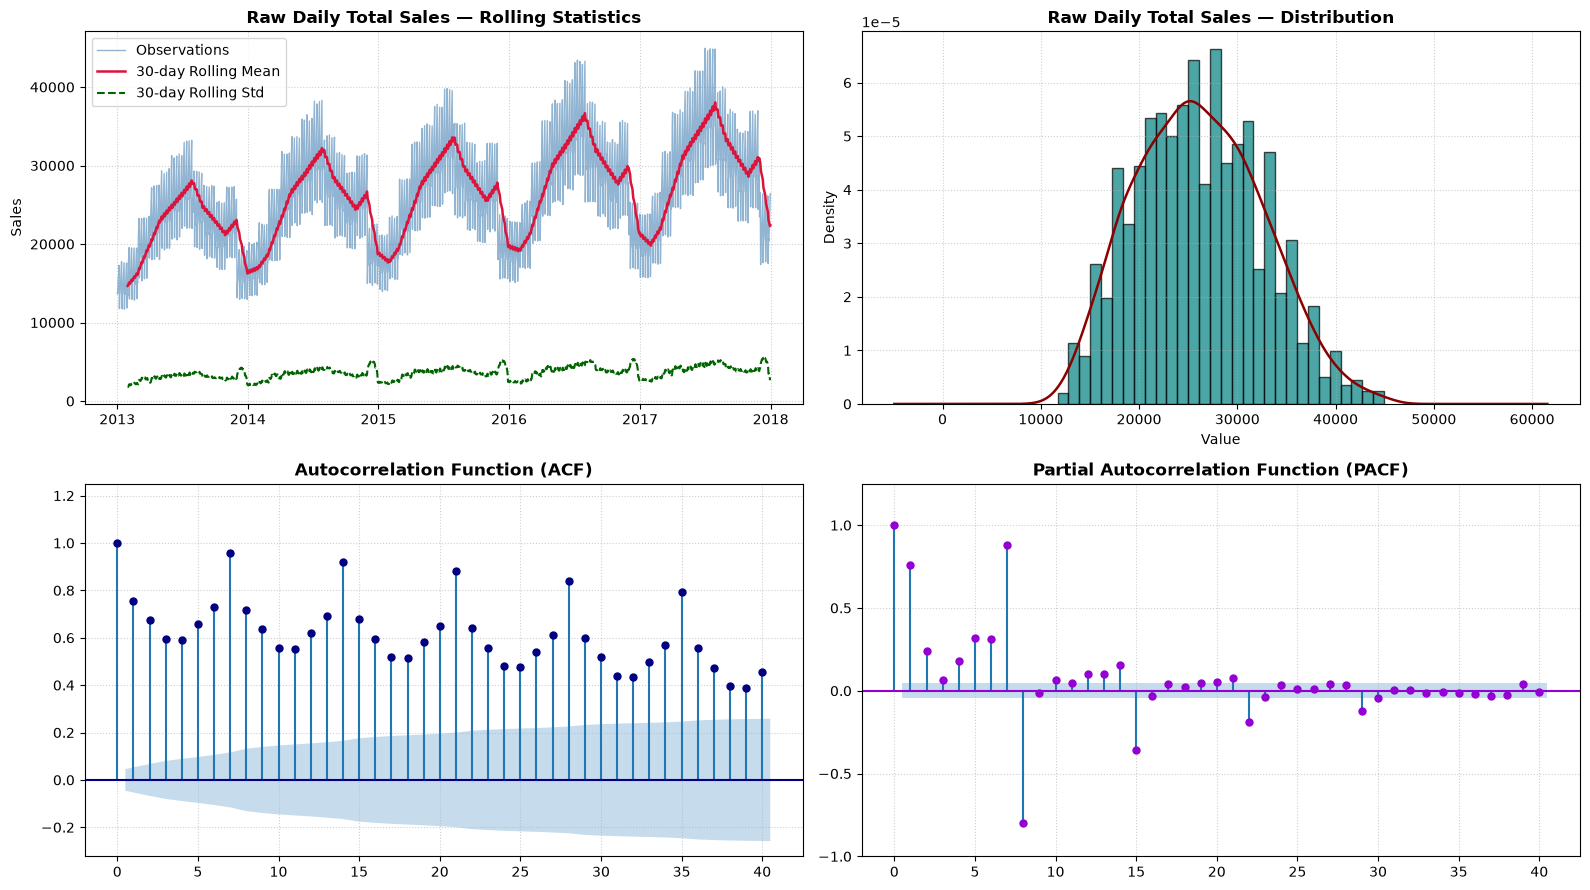

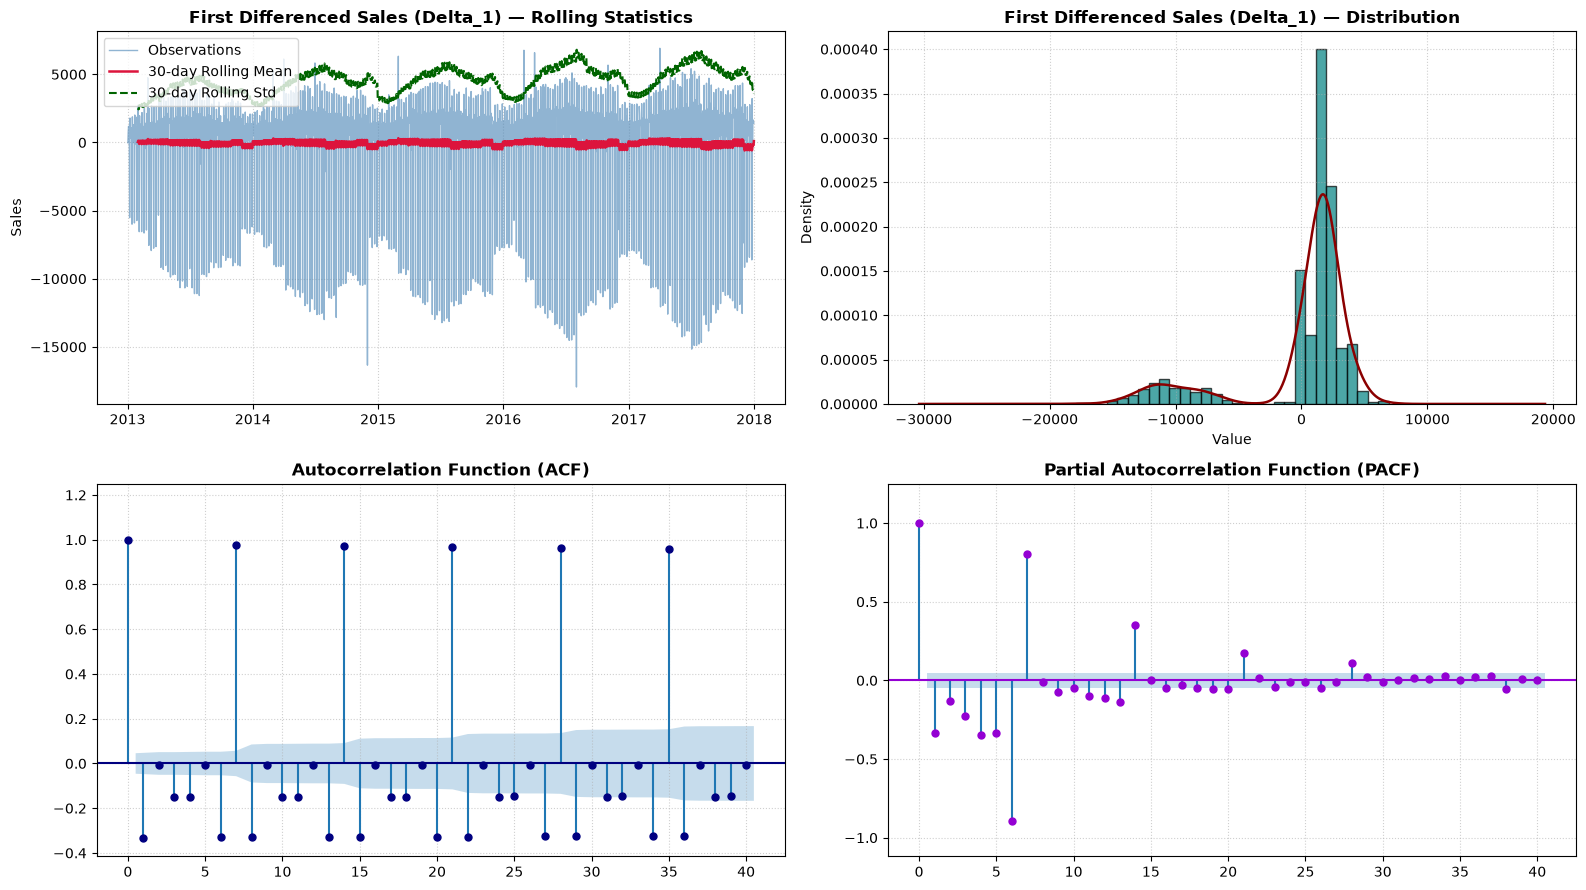

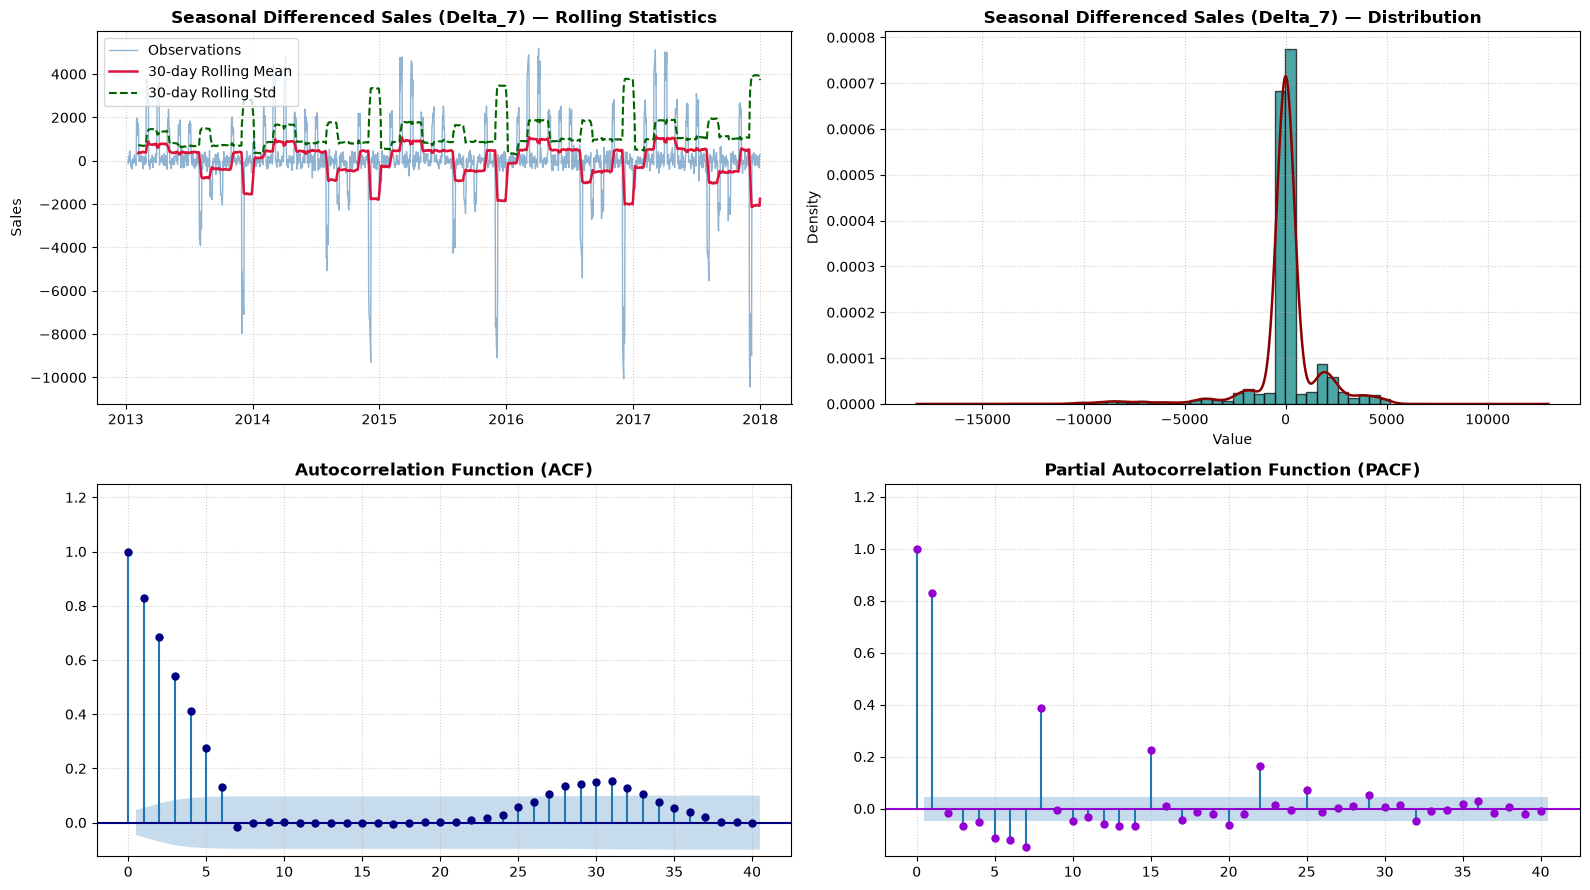

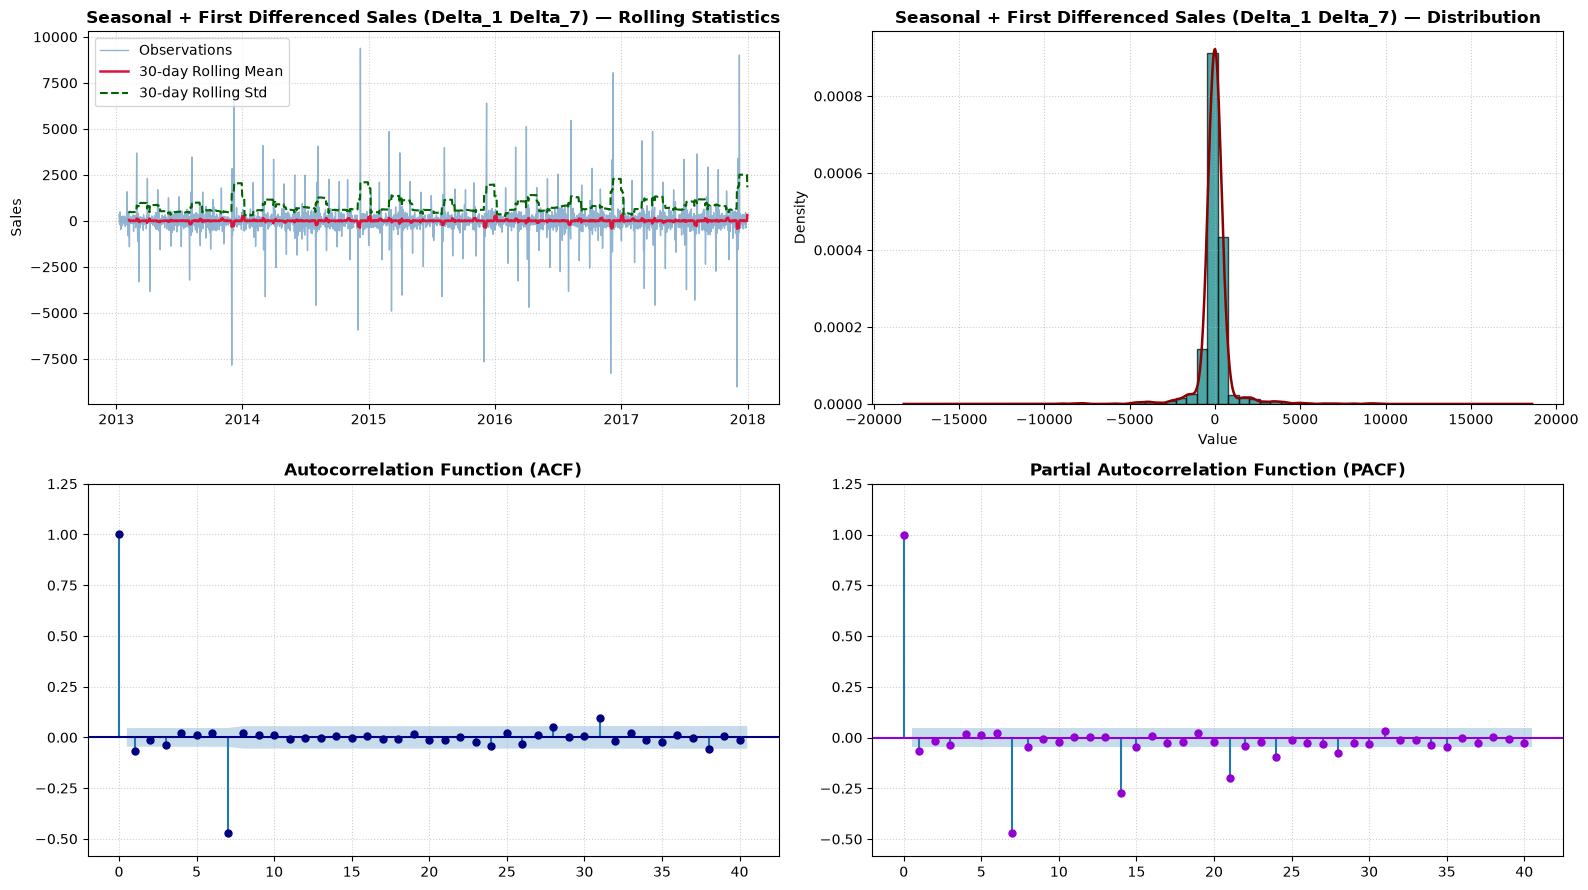

In [2]:
# Comprehensive Stationarity Diagnosis
stationarity_summary = run_stationarity_analysis(daily_sales, save_dir="../outputs/plots")
stationarity_summary

## 2. Key Findings & Differencing Conclusions

- **Raw Sales**: Has an upward secular trend and strong 7-day cyclical oscillations. ADF rejects H0 weakly (=0.0296$) but KPSS rejects H0 strongly (=0.010$). Classified as **Difference Stationary**.
- **First Differencing ($\Delta_1$):** Successfully detrends the series. ADF Stat drops to -8.92 ( < 10^{-5}$) and KPSS fails to reject ( = 0.10$). Confirmed stationary.
- **Seasonal Differencing ($\Delta_7$):** Removes the weekly cycle ( < 10^{-5}$).
- **Combined Differencing ($\Delta_1 \Delta_7$):** Yields strong white-noise residuals ideal for SARIMA and linear modeling.